## Problem Statement

You need to build a model that is able to classify customer complaints based on the products/services. By doing so, you can segregate these tickets into their relevant categories and, therefore, help in the quick resolution of the issue.

You will be doing topic modelling on the <b>.json</b> data provided by the company. Since this data is not labelled, you need to apply NMF to analyse patterns and classify tickets into the following five clusters based on their products/services:

* Credit card / Prepaid card

* Bank account services

* Theft/Dispute reporting

* Mortgages/loans

* Others


With the help of topic modelling, you will be able to map each ticket onto its respective department/category. You can then use this data to train any supervised model such as logistic regression, decision tree or random forest. Using this trained model, you can classify any new customer complaint support ticket into its relevant department.

## Pipelines that needs to be performed:

You need to perform the following eight major tasks to complete the assignment:

1.  Data loading

2. Text preprocessing

3. Exploratory data analysis (EDA)

4. Feature extraction

5. Topic modelling

6. Model building using supervised learning

7. Model training and evaluation

8. Model inference

## Importing the necessary libraries

In [1]:
import json
import numpy as np
import pandas as pd
import re, nltk, spacy, string
import en_core_web_sm
nlp = en_core_web_sm.load()
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from plotly.offline import plot
import plotly.graph_objects as go
import plotly.express as px

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from pprint import pprint

## Loading the data

The data is in JSON format and we need to convert it to a dataframe.

In [2]:
# Opening JSON file
with open('./customer-complaints/complaints-2021-05-14_08_16.json', 'r') as f:
    data = json.load(f)
df=pd.json_normalize(data)

## Data preparation

In [3]:
# Inspect the dataframe to understand the given data.
print(df.shape)
df.head()


(78313, 22)


,_index,_type,_id,_score,_source.tags,_source.zip_code,_source.complaint_id,_source.issue,_source.date_received,_source.state,...,_source.company_response,_source.company,_source.submitted_via,_source.date_sent_to_company,_source.company_public_response,_source.sub_product,_source.timely,_source.complaint_what_happened,_source.sub_issue,_source.consumer_consent_provided
0,complaint-public-v2,complaint,3211475,0.0,None,90301,3211475,Attempts to collect debt not owed,2019-04-13T12:00:00-05:00,CA,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-13T12:00:00-05:00,None,Credit card debt,Yes,,Debt is not yours,Consent not provided
1,complaint-public-v2,complaint,3229299,0.0,Servicemember,319XX,3229299,Written notification about debt,2019-05-01T12:00:00-05:00,GA,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-01T12:00:00-05:00,None,Credit card debt,Yes,Good morning my name is XXXX XXXX and I apprec...,Didn't receive enough information to verify debt,Consent provided
2,complaint-public-v2,complaint,3199379,0.0,None,77069,3199379,"Other features, terms, or problems",2019-04-02T12:00:00-05:00,TX,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-02T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,I upgraded my XXXX XXXX card in XX/XX/2018 and...,Problem with rewards from credit card,Consent provided
3,complaint-public-v2,complaint,2673060,0.0,None,48066,2673060,Trouble during payment process,2017-09-13T12:00:00-05:00,MI,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2017-09-14T12:00:00-05:00,None,Conventional home mortgage,Yes,,None,Consent not provided
4,complaint-public-v2,complaint,3203545,0.0,None,10473,3203545,Fees or interest,2019-04-05T12:00:00-05:00,NY,...,Closed with explanation,JPMORGAN CHASE & CO.,Referral,2019-04-05T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,,Charged too much interest,N/A


In [4]:
#print the column names
print(df.columns.shape)
df.columns

(22,)


Index(['_index', '_type', '_id', '_score', '_source.tags', '_source.zip_code',
       '_source.complaint_id', '_source.issue', '_source.date_received',
       '_source.state', '_source.consumer_disputed', '_source.product',
       '_source.company_response', '_source.company', '_source.submitted_via',
       '_source.date_sent_to_company', '_source.company_public_response',
       '_source.sub_product', '_source.timely',
       '_source.complaint_what_happened', '_source.sub_issue',
       '_source.consumer_consent_provided'],
      dtype='object')

In [5]:
#Assign new column names
df = df[['_source.complaint_what_happened']]
df.columns = ['complaints']
df.head()


,complaints
0,
1,Good morning my name is XXXX XXXX and I apprec...
2,I upgraded my XXXX XXXX card in XX/XX/2018 and...
3,
4,


In [6]:
#Assign nan in place of blanks in the complaints column
condition = df['complaints'] == ''
print(df.shape)
print(df[condition].shape)
df.loc[condition, 'complaints'] = np.nan


(78313, 1)
(57241, 1)


In [7]:
#Remove all rows where complaints column is nan
condition = df['complaints'].isna()
df = df[~condition]
print(df.shape)
df.head()

(21072, 1)


,complaints
1,Good morning my name is XXXX XXXX and I apprec...
2,I upgraded my XXXX XXXX card in XX/XX/2018 and...
10,Chase Card was reported on XX/XX/2019. However...
11,"On XX/XX/2018, while trying to book a XXXX XX..."
14,my grand son give me check for {$1600.00} i de...


## Prepare the text for topic modeling

Once you have removed all the blank complaints, you need to:

* Make the text lowercase
* Remove text in square brackets
* Remove punctuation
* Remove words containing numbers


Once you have done these cleaning operations you need to perform the following:
* Lemmatize the texts
* Extract the POS tags of the lemmatized text and remove all the words which have tags other than NN[tag == "NN"].


In [8]:
# Write your function here to clean the text and remove all the unnecessary elements.
def remove_text_in_square_brackets(text):
    result = text
    pattern = r"\[.*?\]"
    result = re.sub(pattern, "", text)
    return result

def remove_punctuations(text):
    result = text
    pattern = r"[^\w\s]"
    result = re.sub(pattern, "", text)
    return result

def remove_words_containing_numbers(text):
    result = text
    pattern = r"\b\w*\d\w*\b"
    result = re.sub(pattern, "", text).strip()
    return result

def remove_extra_spaces(text):
    result = text
    pattern = r"\s+"
    result = re.sub(pattern, "", text)
    return result

def clean_text(text):
    result = text
    result = text.lower()
    result = remove_text_in_square_brackets(result)
    result = remove_punctuations(result)
    result = remove_words_containing_numbers(result)
    return result

In [9]:
df['complaints'] = df.apply(lambda x: clean_text(x['complaints']), axis=1)

In [10]:
df.shape

(21072, 1)

In [11]:
df.iloc[100,:]['complaints']

'to supervisor i wish to make a complaint regarding the case managment of xxxx xxxx i would like to bring to the attention that mr xxxx failed to properly communicate with me and my representative i received the following calls from mr xxxx     xxxx  at xxxx xxxx he left voice mail \n xxxx  at xxxx xxxx we spoke briefly and i asked him to call back at noon \n xxxx xxxx  at xxxx xxxx he left voice mail \n xxxx  at xxxx xxxx i left voice message for a return call his voice message indicated a return call within  hours \n xxxx  at xxxx xxxx i left another voice messsage for return call \n\ndue to not returning my calls and the importance of my issues i reached out to my representive from xxxx who began making calls to mr xxxx on my behalf i am sure she made notes on the date and time she left several messages there was even a little joke on when mr xxxx was going to return her call she said  watch he is going to call her when he is about to walk out the door  later that day i forgot what 

In [12]:
#Write your function to Lemmatize the texts
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.corpus import wordnet

# Download necessary resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

def lemmatize_text(text):
    lemmatizer = WordNetLemmatizer()
    words = word_tokenize(text)
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    return ' '.join(lemmatized_words)

# Example usage
text = "The cats are running faster than the dogs."
lemmatized_text = lemmatize_text(text)
print(lemmatized_text)


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/suyashkumarsingh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/suyashkumarsingh/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/suyashkumarsingh/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/suyashkumarsingh/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/suyashkumarsingh/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


The cat are running faster than the dog .


In [13]:
#Create a dataframe('df_clean') that will have only the complaints and the lemmatized complaints
df['lemmatized_complaints'] = df.apply(lambda x: lemmatize_text(x['complaints']), axis=1)
df_clean = df[['complaints', 'lemmatized_complaints']]


In [14]:
df_clean

,complaints,lemmatized_complaints
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...
...,...,...
78303,after being a chase card customer for well ove...,after being a chase card customer for well ove...
78309,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx i called chas my xxxx xx...
78310,i am not familiar with xxxx pay and did not un...,i am not familiar with xxxx pay and did not un...
78311,i have had flawless credit for yrs ive had ch...,i have had flawless credit for yr ive had chas...


In [15]:
from nltk.tokenize import word_tokenize
from nltk import pos_tag

words = word_tokenize(df_clean.iloc[0,:]['complaints'])
pos_tags = pos_tag(words)
print(pos_tags)

[('good', 'JJ'), ('morning', 'NN'), ('my', 'PRP$'), ('name', 'NN'), ('is', 'VBZ'), ('xxxx', 'JJ'), ('xxxx', 'NNP'), ('and', 'CC'), ('i', 'JJ'), ('appreciate', 'VBP'), ('it', 'PRP'), ('if', 'IN'), ('you', 'PRP'), ('could', 'MD'), ('help', 'VB'), ('me', 'PRP'), ('put', 'VB'), ('a', 'DT'), ('stop', 'NN'), ('to', 'TO'), ('chase', 'VB'), ('bank', 'NN'), ('cardmember', 'NN'), ('services', 'NNS'), ('in', 'IN'), ('i', 'JJ'), ('wrote', 'VBD'), ('to', 'TO'), ('chase', 'VB'), ('asking', 'VBG'), ('for', 'IN'), ('debt', 'NN'), ('verification', 'NN'), ('and', 'CC'), ('what', 'WP'), ('they', 'PRP'), ('sent', 'VBD'), ('me', 'PRP'), ('a', 'DT'), ('statement', 'NN'), ('which', 'WDT'), ('is', 'VBZ'), ('not', 'RB'), ('acceptable', 'JJ'), ('i', 'NN'), ('am', 'VBP'), ('asking', 'VBG'), ('the', 'DT'), ('bank', 'NN'), ('to', 'TO'), ('validate', 'VB'), ('the', 'DT'), ('debt', 'NN'), ('instead', 'RB'), ('i', 'RB'), ('been', 'VBN'), ('receiving', 'VBG'), ('mail', 'NN'), ('every', 'DT'), ('month', 'NN'), ('from',

In [16]:
#Write your function to extract the POS tags

from nltk.tokenize import word_tokenize
from nltk import pos_tag
# def pos_tag(text):
#     words = word_tokenize(text)
#     return pos_tag(words)

def pos_tag_NN(text):
    result = []
    words = word_tokenize(text)
    pos_tags = pos_tag(words)
    for pt in pos_tags:
        if(pt[1] == 'NN'):
            result.append(pt[0])
    return ' '.join(list(set(result)))

# df_clean["complaint_POS_removed"] =  #this column should contain lemmatized text with all the words removed which have tags other than NN[tag == "NN"].
df_clean["complaint_POS_removed"] = df_clean.apply(lambda x: pos_tag_NN(x['lemmatized_complaints']), axis=1)


In [17]:
df_clean

,complaints,lemmatized_complaints,complaint_POS_removed
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank cardmember i statement debt ...
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...,upgrade card information order xxxx recording ...
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...,card application consent service applicant ide...
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...,card fact bank notification i minute consent s...
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,number son refuse time taking money check clai...
...,...,...,...
78303,after being a chase card customer for well ove...,after being a chase card customer for well ove...,card solicitation wa chase point month decade ...
78309,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx i called chas my xxxx xx...,chas card adjuster daughter time call copy con...
78310,i am not familiar with xxxx pay and did not un...,i am not familiar with xxxx pay and did not un...,mogul brand tab public pi stand bank authority...
78311,i have had flawless credit for yrs ive had ch...,i have had flawless credit for yr ive had chas...,someone card standard experience sum world cha...


In [18]:
#The clean dataframe should now contain the raw complaint, lemmatized complaint and the complaint after removing POS tags.
item = df_clean.iloc[0,:]
print(item['complaints'])
print('=========')
print(item['lemmatized_complaints'])
print('=========')
print(item['complaint_POS_removed'])

good morning my name is xxxx xxxx and i appreciate it if you could help me put a stop to chase bank cardmember services 
in  i wrote to chase asking for debt verification and what they sent me a statement which is not acceptable i am asking the bank to validate the debt instead i been receiving mail every month from them attempting to collect a debt 
i have a right to know this information as a consumer 

chase account  xxxx xxxx xxxx xxxx thanks in advance for your help
good morning my name is xxxx xxxx and i appreciate it if you could help me put a stop to chase bank cardmember service in i wrote to chase asking for debt verification and what they sent me a statement which is not acceptable i am asking the bank to validate the debt instead i been receiving mail every month from them attempting to collect a debt i have a right to know this information a a consumer chase account xxxx xxxx xxxx xxxx thanks in advance for your help
verification bank cardmember i statement debt chase stop

## Exploratory data analysis to get familiar with the data.

Write the code in this task to perform the following:

*   Visualise the data according to the 'Complaint' character length
*   Using a word cloud find the top 40 words by frequency among all the articles after processing the text
*   Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text. ‘




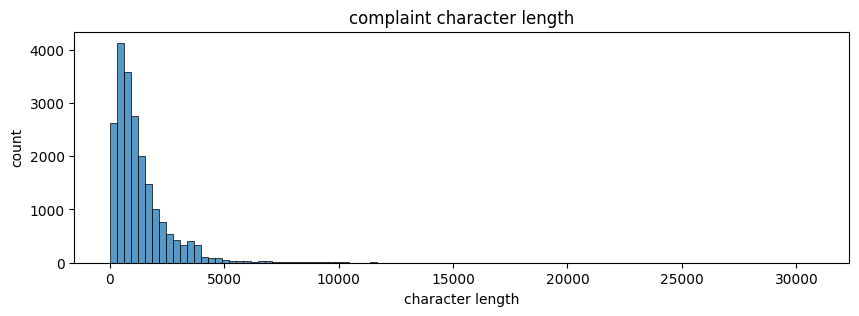

In [19]:
# Write your code here to visualise the data according to the 'Complaint' character length
temp = df_clean.copy()
temp['char_len'] = temp['complaints'].str.len()

plt.figure(figsize=(10,3))
sns.histplot(data = temp, x='char_len', bins=100)
plt.title('complaint character length')
plt.xlabel('character length')
plt.ylabel('count')
plt.show()

#### Find the top 40 words by frequency among all the articles after processing the text.

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/suyashkumarsingh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


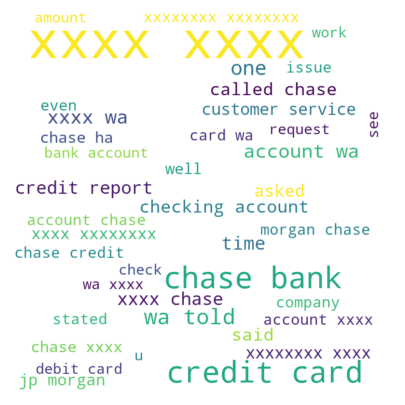

In [20]:
#Using a word cloud find the top 40 words by frequency among all the articles after processing the text
from wordcloud import WordCloud
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    result = text
    words = [word for word in result.split() if word not in stop_words]
    result = ' '.join(words)
    return result

temp = df_clean.copy()
temp['complaints_without_stopwords'] = temp.apply(lambda x: remove_stopwords(x['lemmatized_complaints']), axis=1)

text_corpus = ' '.join(temp['complaints_without_stopwords'])

wordcloud = WordCloud(width=800, height=800, max_words=40, background_color='white').generate(text_corpus)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [21]:
df_clean.columns

Index(['complaints', 'lemmatized_complaints', 'complaint_POS_removed'], dtype='object')

In [22]:
df_clean

,complaints,lemmatized_complaints,complaint_POS_removed
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank cardmember i statement debt ...
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...,upgrade card information order xxxx recording ...
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...,card application consent service applicant ide...
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...,card fact bank notification i minute consent s...
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,number son refuse time taking money check clai...
...,...,...,...
78303,after being a chase card customer for well ove...,after being a chase card customer for well ove...,card solicitation wa chase point month decade ...
78309,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx i called chas my xxxx xx...,chas card adjuster daughter time call copy con...
78310,i am not familiar with xxxx pay and did not un...,i am not familiar with xxxx pay and did not un...,mogul brand tab public pi stand bank authority...
78311,i have had flawless credit for yrs ive had ch...,i have had flawless credit for yr ive had chas...,someone card standard experience sum world cha...


In [23]:
#Removing -PRON- from the text corpus
df_clean['Complaint_clean'] = df_clean['complaint_POS_removed'].str.replace('-PRON-', '')

#### Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text.

In [24]:
#Write your code here to find the top 30 unigram frequency among the complaints in the cleaned datafram(df_clean).
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter

vectorizer = CountVectorizer(ngram_range=(1,1), stop_words='english')
X = vectorizer.fit_transform(df_clean['Complaint_clean'])
unigram_counts = X.toarray().sum(axis=0)
unigram_frequency = dict(zip(vectorizer.get_feature_names_out(), unigram_counts))
unigram_counter = Counter(unigram_frequency)
unigram_counter.most_common(30)


[('chase', 14972),
 ('account', 12487),
 ('xxxx', 12352),
 ('wa', 12240),
 ('credit', 10655),
 ('bank', 10085),
 ('card', 9169),
 ('time', 8518),
 ('day', 6632),
 ('payment', 6560),
 ('ha', 5477),
 ('money', 5382),
 ('xxxxxxxx', 5038),
 ('information', 4975),
 ('month', 4965),
 ('year', 4941),
 ('letter', 4609),
 ('number', 4466),
 ('phone', 4428),
 ('customer', 4367),
 ('charge', 4356),
 ('service', 4283),
 ('company', 4138),
 ('report', 3897),
 ('balance', 3576),
 ('issue', 3501),
 ('fee', 3459),
 ('loan', 3437),
 ('transaction', 3437),
 ('fraud', 3168)]

In [25]:
#Print the top 10 words in the unigram frequency
unigram_counter.most_common(10)


[('chase', 14972),
 ('account', 12487),
 ('xxxx', 12352),
 ('wa', 12240),
 ('credit', 10655),
 ('bank', 10085),
 ('card', 9169),
 ('time', 8518),
 ('day', 6632),
 ('payment', 6560)]

In [26]:
#Write your code here to find the top 30 bigram frequency among the complaints in the cleaned datafram(df_clean).
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter

vectorizer = CountVectorizer(ngram_range=(2,2), stop_words='english')
X = vectorizer.fit_transform(df_clean['Complaint_clean'])
bigram_counts = X.toarray().sum(axis=0)
bigram_frequency = dict(zip(vectorizer.get_feature_names_out(), bigram_counts))
bigram_counter = Counter(bigram_frequency)
bigram_counter.most_common(30)


[('wa chase', 5717),
 ('money xxxx', 2981),
 ('card time', 2442),
 ('ha account', 2092),
 ('account credit', 1708),
 ('bank day', 1680),
 ('xxxx letter', 1183),
 ('loan wa', 1104),
 ('information xxxx', 1095),
 ('bank deposit', 1071),
 ('transaction money', 1044),
 ('consumer credit', 1032),
 ('chase point', 997),
 ('number wa', 986),
 ('loan chase', 974),
 ('email wa', 972),
 ('week credit', 873),
 ('wa hour', 821),
 ('branch account', 820),
 ('number email', 809),
 ('transaction xxxx', 806),
 ('month xxxx', 788),
 ('xxxx representative', 774),
 ('credit chase', 758),
 ('account situation', 756),
 ('information transaction', 730),
 ('time bank', 729),
 ('wa loan', 720),
 ('chase balance', 718),
 ('chase month', 712)]

In [27]:
#Print the top 10 words in the bigram frequency
bigram_counter.most_common(10)

[('wa chase', 5717),
 ('money xxxx', 2981),
 ('card time', 2442),
 ('ha account', 2092),
 ('account credit', 1708),
 ('bank day', 1680),
 ('xxxx letter', 1183),
 ('loan wa', 1104),
 ('information xxxx', 1095),
 ('bank deposit', 1071)]

In [28]:
#Write your code here to find the top 30 trigram frequency among the complaints in the cleaned datafram(df_clean).
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter

vectorizer = CountVectorizer(ngram_range=(3,3), stop_words='english')
X = vectorizer.fit_transform(df_clean['Complaint_clean'])
trigram_counts = X.toarray().sum(axis=0)
trigram_frequency = dict(zip(vectorizer.get_feature_names_out(), trigram_counts))
trigram_counter = Counter(trigram_frequency)
trigram_counter.most_common(30)

[('transaction money xxxx', 722),
 ('loan wa chase', 662),
 ('number wa chase', 532),
 ('email wa chase', 525),
 ('wa chase point', 502),
 ('wa hour chase', 477),
 ('wa loan chase', 426),
 ('bank deposit day', 397),
 ('wa chase month', 349),
 ('information money xxxx', 347),
 ('ha account credit', 345),
 ('wa chase balance', 298),
 ('statement wa chase', 284),
 ('card time bank', 273),
 ('wa chase documentation', 265),
 ('number email wa', 251),
 ('information transaction money', 242),
 ('account week credit', 240),
 ('charge ha account', 233),
 ('wa chase debit', 230),
 ('branch ha account', 229),
 ('hour wa chase', 228),
 ('wa chase thank', 227),
 ('issue wa chase', 223),
 ('day wa chase', 220),
 ('money xxxx representative', 219),
 ('wa chase hold', 219),
 ('month money xxxx', 218),
 ('wa chase checking', 212),
 ('account consumer credit', 211)]

In [29]:
#Print the top 10 words in the trigram frequency
trigram_counter.most_common(10)

[('transaction money xxxx', 722),
 ('loan wa chase', 662),
 ('number wa chase', 532),
 ('email wa chase', 525),
 ('wa chase point', 502),
 ('wa hour chase', 477),
 ('wa loan chase', 426),
 ('bank deposit day', 397),
 ('wa chase month', 349),
 ('information money xxxx', 347)]

## The personal details of customer has been masked in the dataset with xxxx. Let's remove the masked text as this will be of no use for our analysis

In [30]:
df_clean['Complaint_clean'] = df_clean['Complaint_clean'].str.replace('xxxx','')

In [31]:
#All masked texts has been removed
df_clean

,complaints,lemmatized_complaints,complaint_POS_removed,Complaint_clean
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank cardmember i statement debt ...,verification bank cardmember i statement debt ...
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...,upgrade card information order xxxx recording ...,upgrade card information order recording date...
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...,card application consent service applicant ide...,card application consent service applicant ide...
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...,card fact bank notification i minute consent s...,card fact bank notification i minute consent s...
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,number son refuse time taking money check clai...,number son refuse time taking money check clai...
...,...,...,...,...
78303,after being a chase card customer for well ove...,after being a chase card customer for well ove...,card solicitation wa chase point month decade ...,card solicitation wa chase point month decade ...
78309,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx i called chas my xxxx xx...,chas card adjuster daughter time call copy con...,chas card adjuster daughter time call copy con...
78310,i am not familiar with xxxx pay and did not un...,i am not familiar with xxxx pay and did not un...,mogul brand tab public pi stand bank authority...,mogul brand tab public pi stand bank authority...
78311,i have had flawless credit for yrs ive had ch...,i have had flawless credit for yr ive had chas...,someone card standard experience sum world cha...,someone card standard experience sum world cha...


## Feature Extraction
Convert the raw texts to a matrix of TF-IDF features

**max_df** is used for removing terms that appear too frequently, also known as "corpus-specific stop words"
max_df = 0.95 means "ignore terms that appear in more than 95% of the complaints"

**min_df** is used for removing terms that appear too infrequently
min_df = 2 means "ignore terms that appear in less than 2 complaints"

In [32]:
#Write your code here to initialise the TfidfVectorizer
tfidf = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')


#### Create a document term matrix using fit_transform

The contents of a document term matrix are tuples of (complaint_id,token_id) tf-idf score:
The tuples that are not there have a tf-idf score of 0

In [33]:
#Write your code here to create the Document Term Matrix by transforming the complaints column present in df_clean.
X = tfidf.fit_transform(df_clean['Complaint_clean'])
df = pd.DataFrame(X.toarray(), columns=tfidf.get_feature_names_out())
df


,__,___,____,aa,aarp,ab,abandonment,abatement,abbreviation,abd,...,youth,youve,yr,ytd,zero,zeroed,zip,zipcode,zombie,zone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21067,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21068,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21069,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21070,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [34]:
df_clean.shape

(21072, 4)

## Topic Modelling using NMF

Non-Negative Matrix Factorization (NMF) is an unsupervised technique so there are no labeling of topics that the model will be trained on. The way it works is that, NMF decomposes (or factorizes) high-dimensional vectors into a lower-dimensional representation. These lower-dimensional vectors are non-negative which also means their coefficients are non-negative.

In this task you have to perform the following:

* Find the best number of clusters
* Apply the best number to create word clusters
* Inspect & validate the correction of each cluster wrt the complaints
* Correct the labels if needed
* Map the clusters to topics/cluster names

In [35]:
from sklearn.decomposition import NMF

## Manual Topic Modeling
You need to do take the trial & error approach to find the best num of topics for your NMF model.

The only parameter that is required is the number of components i.e. the number of topics we want. This is the most crucial step in the whole topic modeling process and will greatly affect how good your final topics are.

In [36]:
#Load your nmf_model with the n_components i.e 5
# num_topics = #write the value you want to test out
num_topics = 15

#keep the random_state =40
# nmf_model = #write your code here
nmf_model = NMF(n_components=num_topics, random_state=40)

In [37]:
W = nmf_model.fit_transform(X) # document-topic matrix
H = nmf_model.components_ # topic-term matrix

words = np.array(tfidf.get_feature_names_out())

/Users/suyashkumarsingh/.pyenv/versions/tensorflow/lib/python3.11/site-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning:

Maximum number of iterations 200 reached. Increase it to improve convergence.



In [38]:
print(W.shape)
W

(21072, 15)


array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.03102145],
       [0.00569379, 0.        , 0.        , ..., 0.00861791, 0.        ,
        0.01942263],
       [0.        , 0.00215357, 0.        , ..., 0.08377114, 0.        ,
        0.        ],
       ...,
       [0.01259801, 0.01148245, 0.0029203 , ..., 0.02388809, 0.00201027,
        0.0103769 ],
       [0.0036308 , 0.        , 0.01154188, ..., 0.        , 0.00105316,
        0.        ],
       [0.        , 0.0530363 , 0.01948362, ..., 0.        , 0.00267573,
        0.03767448]])

In [39]:
print(H.shape)
H

(15, 6966)


array([[9.10608707e-04, 3.36829298e-04, 3.26015899e-03, ...,
        3.66601220e-04, 0.00000000e+00, 4.26374103e-03],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        2.37122507e-04, 6.25239600e-04, 5.10628313e-03],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 1.97700200e-04, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 3.42457458e-03],
       [5.20608508e-06, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

In [40]:
#Print the Top15 words for each of the topics
topic_words = pd.DataFrame(
    np.zeros((num_topics, 15)),
    index=[f'Topic {i + 1}' for i in range(num_topics)],
    columns = [f'Word {i + 1}' for i in range(15)]
).astype(str)

for i in range(num_topics):
    ix = H[i].argsort()[::-1][:15]
    topic_words.iloc[i] = words[ix]

topic_words

,Word 1,Word 2,Word 3,Word 4,Word 5,Word 6,Word 7,Word 8,Word 9,Word 10,Word 11,Word 12,Word 13,Word 14,Word 15
Topic 1,issue,complaint,time,day,week,letter,response,point,office,request,case,representative,supervisor,department,process
Topic 2,report,credit,bureau,auto,police,day,item,thought,payment,result,havent,regard,investigation,jpmcb,error
Topic 3,loan,mortgage,home,modification,year,payment,property,house,foreclosure,chase,sale,rate,ha,income,lender
Topic 4,card,credit,chase,score,freedom,limit,year,purchase,wa,point,application,rate,reward,offer,user
Topic 5,transaction,money,claim,debit,fraud,atm,bank,investigation,police,withdrawal,department,wa,pin,transfer,dollar
Topic 6,inquiry,authorization,application,jpmcb,date,credit,knowledge,bank,score,permission,organization,consent,alert,im,file
Topic 7,charge,dispute,merchant,refund,purchase,item,billing,wa,chase,statement,ha,documentation,investigation,letter,proof
Topic 8,balance,payment,fee,month,statement,date,time,wa,day,transfer,pay,overdraft,auto,account,rate
Topic 9,debt,reporting,bureau,agency,collection,consumer,act,information,law,violation,letter,creditor,proof,section,ha
Topic 10,company,business,time,resolution,problem,insurance,record,payment,proof,contract,research,car,policy,knowledge,mark


In [41]:
#Create the best topic for each complaint in terms of integer value 0,1,2,3 & 4
topic_mapping = {
    'Topic 4': 'Credit card / Prepaid card',
    'Topic 8': 'Bank account services',
    'Topic 13': 'Theft/Dispute reporting',
    'Topic 3': 'Mortgages/loans',
    'Topic 11': 'Others'
}


In [42]:
#Assign the best topic to each of the cmplaints in Topic Column
W = pd.DataFrame(W, columns=[f'Topic {i + 1}' for i in range(num_topics)])


In [43]:
W

,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10,Topic 11,Topic 12,Topic 13,Topic 14,Topic 15
0,0.000000,0.000000,0.000000,0.000791,0.002300,0.000000,0.000000,0.022633,0.064110,0.000482,0.031646,0.011556,0.000000,0.000000,0.031021
1,0.005694,0.000000,0.000000,0.029570,0.000000,0.004023,0.004926,0.009102,0.009021,0.000000,0.000866,0.016775,0.008618,0.000000,0.019423
2,0.000000,0.002154,0.000000,0.066236,0.000000,0.007913,0.000000,0.000000,0.000000,0.000000,0.040210,0.000000,0.083771,0.000000,0.000000
3,0.028361,0.031347,0.000000,0.030510,0.000000,0.004338,0.004107,0.003924,0.006821,0.000000,0.002173,0.006486,0.002530,0.000000,0.023962
4,0.000000,0.000000,0.005530,0.000000,0.025187,0.001111,0.002870,0.003289,0.000000,0.000913,0.000000,0.021322,0.000000,0.072703,0.032105
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21067,0.004278,0.000000,0.007154,0.044506,0.000000,0.000000,0.024777,0.035820,0.000000,0.000000,0.022573,0.000000,0.000000,0.000000,0.016510
21068,0.023512,0.000898,0.008998,0.021067,0.008861,0.000000,0.011678,0.002574,0.006934,0.001639,0.002686,0.007804,0.000452,0.004838,0.000000
21069,0.012598,0.011482,0.002920,0.000000,0.003167,0.021974,0.004281,0.000000,0.008185,0.000419,0.021164,0.018284,0.023888,0.002010,0.010377
21070,0.003631,0.000000,0.011542,0.032077,0.002354,0.000000,0.000000,0.037974,0.000000,0.000000,0.004075,0.005405,0.000000,0.001053,0.000000


In [44]:
W['max_topic'] = W.apply(lambda x: topic_mapping.get(x.idxmax(), 'Others'), axis=1)

In [45]:
W.shape

(21072, 16)

In [46]:
W[pd.notnull(W['max_topic'])].head(10)

df_clean.loc[:,'Topic'] = W.loc[:,'max_topic']

In [47]:
df_clean.head()

,complaints,lemmatized_complaints,complaint_POS_removed,Complaint_clean,Topic
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank cardmember i statement debt ...,verification bank cardmember i statement debt ...,Credit card / Prepaid card
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...,upgrade card information order xxxx recording ...,upgrade card information order recording date...,Theft/Dispute reporting
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...,card application consent service applicant ide...,card application consent service applicant ide...,Others
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...,card fact bank notification i minute consent s...,card fact bank notification i minute consent s...,Others
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,number son refuse time taking money check clai...,number son refuse time taking money check clai...,Credit card / Prepaid card


In [48]:
df_clean.shape

(21072, 5)

In [49]:
#Print the first 5 Complaint for each of the Topics
df_clean_grouped=df_clean.groupby('Topic').head(5)
df_clean_grouped.sort_values('Topic')

,complaints,lemmatized_complaints,complaint_POS_removed,Complaint_clean,Topic
162,i came to know about the hard inquiry on my cr...,i came to know about the hard inquiry on my cr...,card information score i inquiry service credit,card information score i inquiry service credit,Bank account services
153,i went to the chase atm located xxxx xxxx xxxx...,i went to the chase atm located xxxx xxxx xxxx...,atm dollar customer bill matter didnt deposit ...,atm dollar customer bill matter didnt deposit ...,Bank account services
93,on we purchased a service with xxxx xxxx xxxx...,on we purchased a service with xxxx xxxx xxxx ...,thru card time call day i issue wa chase word ...,thru card time call day i issue wa chase word ...,Bank account services
86,a student loan with chase bank they sold there...,a student loan with chase bank they sold there...,one department response attempt bank report le...,one department response attempt bank report le...,Bank account services
24,mishandling of this account by chase auto and ...,mishandling of this account by chase auto and ...,mishandling xxxx auto account,mishandling auto account,Bank account services
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank cardmember i statement debt ...,verification bank cardmember i statement debt ...,Credit card / Prepaid card
83,unknown inquire reported on my credit bureau s...,unknown inquire reported on my credit bureau s...,bureau xxxx date auto inquire company credit,bureau date auto inquire company credit,Credit card / Prepaid card
73,i have wired through one of chase branches in ...,i have wired through one of chase branch in xx...,time amount bank product i issue default id ch...,time amount bank product i issue default id ch...,Credit card / Prepaid card
40,xxxx xxxx a sofa love seat table and chairs an...,xxxx xxxx a sofa love seat table and chair and...,debit love furniture card table xxxx claim sea...,debit love furniture card table claim seat ba...,Credit card / Prepaid card
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,number son refuse time taking money check clai...,number son refuse time taking money check clai...,Credit card / Prepaid card


#### After evaluating the mapping, if the topics assigned are correct then assign these names to the relevant topic:
* Bank Account services
* Credit card or prepaid card
* Theft/Dispute Reporting
* Mortgage/Loan
* Others

In [ ]:
#Create the dictionary of Topic names and Topics

Topic_names = {   }
#Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)

In [50]:
df_clean

,complaints,lemmatized_complaints,complaint_POS_removed,Complaint_clean,Topic
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank cardmember i statement debt ...,verification bank cardmember i statement debt ...,Credit card / Prepaid card
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...,upgrade card information order xxxx recording ...,upgrade card information order recording date...,Theft/Dispute reporting
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...,card application consent service applicant ide...,card application consent service applicant ide...,Others
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...,card fact bank notification i minute consent s...,card fact bank notification i minute consent s...,Others
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,number son refuse time taking money check clai...,number son refuse time taking money check clai...,Credit card / Prepaid card
...,...,...,...,...,...
78303,after being a chase card customer for well ove...,after being a chase card customer for well ove...,card solicitation wa chase point month decade ...,card solicitation wa chase point month decade ...,NaN
78309,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx i called chas my xxxx xx...,chas card adjuster daughter time call copy con...,chas card adjuster daughter time call copy con...,NaN
78310,i am not familiar with xxxx pay and did not un...,i am not familiar with xxxx pay and did not un...,mogul brand tab public pi stand bank authority...,mogul brand tab public pi stand bank authority...,NaN
78311,i have had flawless credit for yrs ive had ch...,i have had flawless credit for yr ive had chas...,someone card standard experience sum world cha...,someone card standard experience sum world cha...,NaN


## Supervised model to predict any new complaints to the relevant Topics.

You have now build the model to create the topics for each complaints.Now in the below section you will use them to classify any new complaints.

Since you will be using supervised learning technique we have to convert the topic names to numbers(numpy arrays only understand numbers)

In [ ]:
#Create the dictionary again of Topic names and Topics

Topic_names = {   }
#Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)

In [141]:
df_clean

,complaints,lemmatized_complaints,complaint_POS_removed,Complaint_clean,Topic
1,good morning my name is xxxx xxxx and i apprec...,good morning my name is xxxx xxxx and i apprec...,verification bank consumer statement right ser...,verification bank consumer statement right ser...,Credit card / Prepaid card
2,i upgraded my xxxx xxxx card in and was told ...,i upgraded my xxxx xxxx card in and wa told by...,date agent order xxxxxxxx i xxxx information a...,date agent order i information account wa co...,Theft/Dispute reporting
10,chase card was reported on however fraudulent...,chase card wa reported on however fraudulent a...,credit service identity wa consent application...,credit service identity wa consent application...,Others
11,on while trying to book a xxxx xxxx ticket ...,on while trying to book a xxxx xxxx ticket i c...,minute book request bank application statement...,minute book request bank application statement...,Others
14,my grand son give me check for i deposit it i...,my grand son give me check for i deposit it in...,taking deposit time owner date son money numbe...,taking deposit time owner date son money numbe...,Credit card / Prepaid card
15,can you please remove inquiry,can you please remove inquiry,inquiry,inquiry,Others
17,with out notice jp morgan chase restricted my ...,with out notice jp morgan chase restricted my ...,branch day time protocol livelihood situation ...,branch day time protocol livelihood situation ...,Others
20,during the summer months i experience a declin...,during the summer month i experience a decline...,avail week conference reason director situatio...,avail week conference reason director situatio...,Others
23,i have a chase credit card which is incorrectl...,i have a chase credit card which is incorrectl...,credit issue card chase company report,credit issue card chase company report,Mortgages/loans
24,mishandling of this account by chase auto and ...,mishandling of this account by chase auto and ...,account mishandling xxxx auto,account mishandling auto,Bank account services


In [51]:
#Keep the columns"complaint_what_happened" & "Topic" only in the new dataframe --> training_data
training_data= df_clean[['complaints', 'Topic']]
training_data.loc[training_data['Topic'].isna(), 'Topic'] = 'Others'

In [52]:
training_data

,complaints,Topic
1,good morning my name is xxxx xxxx and i apprec...,Credit card / Prepaid card
2,i upgraded my xxxx xxxx card in and was told ...,Theft/Dispute reporting
10,chase card was reported on however fraudulent...,Others
11,on while trying to book a xxxx xxxx ticket ...,Others
14,my grand son give me check for i deposit it i...,Credit card / Prepaid card
...,...,...
78303,after being a chase card customer for well ove...,Others
78309,on wednesday xxxxxxxx i called chas my xxxx xx...,Others
78310,i am not familiar with xxxx pay and did not un...,Others
78311,i have had flawless credit for yrs ive had ch...,Others


In [53]:
training_data['Topic'].shape

(21072,)

#### Apply the supervised models on the training data created. In this process, you have to do the following:
* Create the vector counts using Count Vectoriser
* Transform the word vecotr to tf-idf
* Create the train & test data using the train_test_split on the tf-idf & topics


In [54]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
#Write your code to get the Vector count
count_vectorizer = CountVectorizer()
word_count_matrix = count_vectorizer.fit_transform(training_data['complaints'])


#Write your code here to transform the word vector to tf-idf
tfidf_transformer = TfidfTransformer()
tfidf_matrix = tfidf_transformer.fit_transform(word_count_matrix)
X = pd.DataFrame(tfidf_matrix.toarray(), columns=count_vectorizer.get_feature_names_out())

In [55]:
X['Topic'] = training_data['Topic']

In [56]:
X.loc[X['Topic'].isna(), 'Topic'] = 'Others'

You have to try atleast 3 models on the train & test data from these options:
* Logistic regression
* Decision Tree
* Random Forest
* Naive Bayes (optional)

**Using the required evaluation metrics judge the tried models and select the ones performing the best**

In [57]:
# Write your code here to build any 3 models and evaluate them using the required metrics
import pandas as pd
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X.drop(columns=['Topic']), X['Topic'], test_size=0.2, random_state=42)
X_train_scaled = X_train
X_test_scaled = X_test

In [64]:
model_comparision_df = pd.DataFrame()
models = {}

def add_to_model_comparision(model_name, evaluation_results):
    global model_comparision_df
    new_df = pd.DataFrame([evaluation_results], index=[model_name])
    model_comparision_df = pd.concat([model_comparision_df, new_df], axis=0)

def get_evaluation_results(confusion_matrix, actual, prediction):
    confusion_matrix = confusion_matrix(actual, prediction)

    #                   predicted
    #              non-churn    churn
    #  Actual
    # non-churn      TN           FP    
    # churn          FN           TP

    result = {}
    TN  = confusion_matrix[0][0]
    FP  = confusion_matrix[0][1]
    FN  = confusion_matrix[1][0]
    TP  = confusion_matrix[1][1]

    accuracy                    = (TN + TP)/float(TN + FP + FN + TP) # correctly-predicted/all-predictions
    sensitivity                 = TP/float(FN + TP)                  # correctly-predicted-positives/all-actual-positives
    TPR                         = TP/float(FN + TP)                  # correctly-predicted-positives/all-actual-positives
    recall                      = TP/float(FN + TP)                  # correctly-predicted-positives/all-actual-positives
    specificity                 = TN/float(TN + FP)                  # correctly-predicted-negatives/all-actual-negatives
    FPR                         = FP/float(TN + FP)                  # incorrectly-predicted-positives/all-actual-negatives
    precision                   = TP/float(TP+FP)                    # correctly-predicted-positives/all-predicted-positives  
    negative_predictive_value   = TN/float(TN+FN)                    # correctly-predicted-negatives/all-predicted-negatives
    F1_score                    = 2 * ((precision * recall)/float(precision + recall)) # harmonic mean of precision and recall

    result['accuracy'] = round(accuracy, 2)
    result['sensitivity'] = round(sensitivity, 2)
    result['TPR'] = round(TPR, 2)
    result['recall'] = round(recall, 2)
    result['specificity'] = round(specificity, 2)
    result['FPR'] = round(FPR, 2)
    result['precision'] = round(precision, 2)
    result['negative_predictive_value'] = round(negative_predictive_value, 2)
    result['F1_score'] = round(F1_score, 2)

    return result

In [65]:
%%time

model_name = 'LogisticRegression'

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

classifier = LogisticRegression(random_state=37)
classifier.fit(X_train_scaled, y_train)

y_pred = classifier.predict(X_test_scaled)
evaluation_results = get_evaluation_results(confusion_matrix, y_test, y_pred)
add_to_model_comparision(model_name, evaluation_results)

model_comparision_df

CPU times: user 12min 52s, sys: 3min 58s, total: 16min 51s
Wall time: 1min 26s


,accuracy,sensitivity,TPR,recall,specificity,FPR,precision,negative_predictive_value,F1_score
LogisticRegression,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0


In [66]:
%%time

model_name = 'PCA + LogisticRegression'

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

pca = PCA(0.95, random_state=37)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

classifier = LogisticRegression(random_state=37)
classifier.fit(X_train_pca, y_train)

y_pred = classifier.predict(X_test_pca)
evaluation_results = get_evaluation_results(confusion_matrix, y_test, y_pred)
add_to_model_comparision(model_name, evaluation_results)

model_comparision_df

CPU times: user 2h 56min 20s, sys: 46min 35s, total: 3h 42min 55s
Wall time: 18min 12s


,accuracy,sensitivity,TPR,recall,specificity,FPR,precision,negative_predictive_value,F1_score
LogisticRegression,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
PCA + LogisticRegression,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0


In [67]:
%%time
model_name = 'DecisionTreeClassifier'

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

classifier = DecisionTreeClassifier(random_state=37)
classifier.fit(X_train_scaled, y_train)

y_pred = classifier.predict(X_test_scaled)
evaluation_results = get_evaluation_results(confusion_matrix, y_test, y_pred)
add_to_model_comparision(model_name, evaluation_results)

model_comparision_df

CPU times: user 2min 50s, sys: 1.02 s, total: 2min 51s
Wall time: 2min 51s


,accuracy,sensitivity,TPR,recall,specificity,FPR,precision,negative_predictive_value,F1_score
LogisticRegression,1.00,1.00,1.00,1.00,1.00,0.00,1.0,1.00,1.00
PCA + LogisticRegression,1.00,1.00,1.00,1.00,1.00,0.00,1.0,1.00,1.00
DecisionTreeClassifier,0.85,0.86,0.86,0.86,0.82,0.18,0.9,0.75,0.88


In [68]:
%%time
model_name = 'Random Forest + GridSearchCV'

# GridSearchCV + Random Forest
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

classifier = RandomForestClassifier(random_state=37)
params = {
    'max_depth': [15,35,55,75,85],
    'min_samples_leaf': [5,10,20,50,100,200],
    'n_estimators': [10, 25, 50, 100]
}
cv_search = GridSearchCV(estimator=classifier, param_grid=params, cv = 4, verbose=3, scoring="accuracy")
cv_search.fit(X_train_scaled, y_train)

print(f'grid_search best score: {cv_search.best_score_}')
model = cv_search.best_estimator_

y_pred = model.predict(X_test_scaled)
evaluation_results = get_evaluation_results(confusion_matrix, y_test, y_pred)
add_to_model_comparision(model_name, evaluation_results)

model_comparision_df


Fitting 4 folds for each of 120 candidates, totalling 480 fits
[CV 1/4] END max_depth=15, min_samples_leaf=5, n_estimators=10;, score=0.874 total time=   3.9s
[CV 2/4] END max_depth=15, min_samples_leaf=5, n_estimators=10;, score=0.875 total time=   4.0s
[CV 3/4] END max_depth=15, min_samples_leaf=5, n_estimators=10;, score=0.875 total time=   4.1s
[CV 4/4] END max_depth=15, min_samples_leaf=5, n_estimators=10;, score=0.875 total time=   4.2s
[CV 1/4] END max_depth=15, min_samples_leaf=5, n_estimators=25;, score=0.874 total time=   9.0s
[CV 2/4] END max_depth=15, min_samples_leaf=5, n_estimators=25;, score=0.875 total time=   9.2s
[CV 3/4] END max_depth=15, min_samples_leaf=5, n_estimators=25;, score=0.875 total time=   9.1s
[CV 4/4] END max_depth=15, min_samples_leaf=5, n_estimators=25;, score=0.875 total time=   9.1s
[CV 1/4] END max_depth=15, min_samples_leaf=5, n_estimators=50;, score=0.874 total time=  17.4s
[CV 2/4] END max_depth=15, min_samples_leaf=5, n_estimators=50;, score=0.

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:24: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:25: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:26: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:27: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:28: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:29: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T/ipykernel_33838/429268079.py:30: RuntimeWarning:

invalid value encountered in divide

/var/folders/w1/1vybnxrx6t16f0__7k0t0_8m0000gn/T

,accuracy,sensitivity,TPR,recall,specificity,FPR,precision,negative_predictive_value,F1_score
LogisticRegression,1.00,1.00,1.00,1.00,1.00,0.00,1.0,1.00,1.00
PCA + LogisticRegression,1.00,1.00,1.00,1.00,1.00,0.00,1.0,1.00,1.00
DecisionTreeClassifier,0.85,0.86,0.86,0.86,0.82,0.18,0.9,0.75,0.88
Random Forest + GridSearchCV,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Conclusion

- RandomForest is our final model with an accuracy of about 87%